# Category Recommendation and Market Basket Analysis in Olist’s E-commerce

In [1]:
# Load the libraries

from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from IPython.display import display, Markdown, HTML

In [2]:
import warnings 
warnings.filterwarnings('ignore')

## Database
<div style="width: 700px; text-align: justify; text-justify: inter-word;">
 <p>Olist’s data is divided in multiple datasets. This approach was adopted to facilitate understanding and organization.</p>

 <p>The Olist database consists of 9 files, following an analysis, the following were selected:</p>
     
* olist_orders_dataset
* olist_customers_dataset
* olist_order_items_dataset
* olist_products_dataset
  
<p>Combining these files makes it possible to identify which categories appear in each order, as well as to track purchases made by individual customers over time.</p>

  https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce
</div>

In [3]:
# Load dataset into a DataFrame
orders = pd.read_csv("olist_orders_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
items = pd.read_csv("olist_order_items_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")

# Print number of rows and columns in dataset
print("orders:", orders.shape)  
print("customers:",customers.shape) 
print("items:", items.shape) 
print("products:", products.shape) 

orders: (99441, 8)
customers: (99441, 5)
items: (112650, 7)
products: (32951, 9)


In [4]:
# Reading of the files with selected columns

orders = pd.read_csv("olist_orders_dataset.csv",
    usecols=["order_id", "customer_id", "order_status", "order_purchase_timestamp"],)

customers = pd.read_csv("olist_customers_dataset.csv",
    usecols=["customer_id", "customer_unique_id", "customer_state"],)


items = pd.read_csv("olist_order_items_dataset.csv",
    usecols=["order_id", "order_item_id", "product_id"],)


products = pd.read_csv("olist_products_dataset.csv",
    usecols=["product_id", "product_category_name", "product_photos_qty",
        "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm",],)


display (HTML("<strong>Orders</strong>"))
display(orders.head())

display (HTML("<strong>Customers</strong>"))
display(customers.head())

display (HTML("<strong>Items</strong>"))
display(items.head())

display (HTML("<strong>Products</strong>"))
display(products.head(10))


,order_id,customer_id,order_status,order_purchase_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39


,customer_id,customer_unique_id,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,SP


,order_id,order_item_id,product_id
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089


,product_id,product_category_name,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,4.0,625.0,20.0,17.0,13.0
5,41d3672d4792049fa1779bb35283ed13,instrumentos_musicais,1.0,200.0,38.0,5.0,11.0
6,732bd381ad09e530fe0a5f457d81becb,cool_stuff,4.0,18350.0,70.0,24.0,44.0
7,2548af3e6e77a690cf3eb6368e9ab61e,moveis_decoracao,2.0,900.0,40.0,8.0,40.0
8,37cc742be07708b53a98702e77a21a02,eletrodomesticos,1.0,400.0,27.0,13.0,17.0
9,8c92109888e8cdf9d66dc7e463025574,brinquedos,1.0,600.0,17.0,10.0,12.0


### Data Preparation

In [5]:
order_orig = orders.copy()

# 1. Check that the keys are populated and unique

assert orders["order_id"].notna().all() and orders["order_id"].is_unique
assert customers["customer_id"].notna().all() and customers["customer_id"].is_unique
assert products["product_id"].notna().all() and products["product_id"].is_unique

# Check the combination of order and item position

assert not items.duplicated(["order_id", "order_item_id"]).any()

# 2. Purchase date conversion

orders["order_purchase_timestamp"] = pd.to_datetime( orders["order_purchase_timestamp"], errors="coerce")

# 3. Selects delivered orders with a valid date

delivered = orders.loc[orders["order_status"] == "delivered"].copy()

delivered_dated = delivered.dropna(subset=["order_purchase_timestamp"]).copy()

# 4. Consolidates information from the selected orders

purchases = (delivered_dated.merge(customers,
        on="customer_id",
        how="left",
        validate="many_to_one").merge(items,
        on="order_id",
        how="left",
        validate="one_to_many").merge(products,
        on="product_id",
        how="left",
        validate="many_to_one"))

# 5. Standardize category and remove rows without a category

purchases ["product_category_name"] = (purchases["product_category_name"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA))

with_category = purchases.dropna(subset=["product_category_name"]).copy()

# 6. Check how many orders remained at each stage
audit = pd.Series({
    "Origin orders": orders["order_id"].nunique(),
    "Orders delivered": delivered["order_id"].nunique(),
    "Orders delivered with a valid date": delivered_dated["order_id"].nunique(),
    "Orders with at least one category": with_category["order_id"].nunique(),}, name="Orders").to_frame()

audit["Removed orders"] = (-audit["Orders"].diff().fillna(0)).astype(int)

display(audit)

,Orders,Removed orders
Origin orders,99441,0
Orders delivered,96478,2963
Orders delivered with a valid date,96478,0
Orders with at least one category,95146,1332


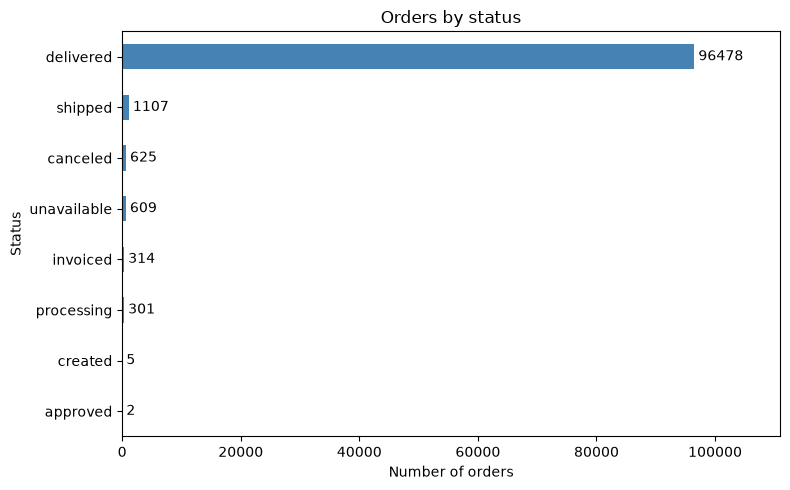

In [6]:
orders_by_status = (orders.groupby("order_status")["order_id"]
    .nunique()
    .sort_values())

ax = orders_by_status.plot.barh(figsize=(8, 5), color="steelblue")

ax.set_title("Orders by status")
ax.set_xlabel("Number of orders")
ax.set_ylabel("Status")
ax.bar_label(ax.containers[0], padding=3)
ax.margins(x=0.15)

plt.tight_layout()
plt.show()

## Baskets and recurring orders

In [7]:
category = "product_category_name"
customer = "customer_unique_id"
purchase_date = "order_purchase_timestamp"

category_records = with_category.drop_duplicates(["order_id", category]).copy()

basket = category_records.groupby("order_id")[category].agg(set)
basket_size = basket.str.len()

history = category_records.dropna(subset=[customer]).copy()

orders_per_customer = history.groupby(customer)["order_id"].nunique()

print("Purchase dates within selected period:", category_records[purchase_date].min(), "a", category_records[purchase_date].max())
print("Orders in period:", len(basket))
print("Orders with two or more categories:", basket_size.ge(2).sum())
print("Perc order:",  f"{(basket_size >= 2).mean():.2%}")
print("Category:", category_records[category].nunique())
print("Orders without a persistent customer:", category_records.loc[category_records[customer].isna(), "order_id"].nunique())
print("Identified customers:", len(orders_per_customer))
print("Customers with two or more orders:", orders_per_customer.ge(2).sum())
print("Perc customer:", f"{(orders_per_customer >= 2).mean():.2%}")

basket_size.value_counts().sort_index().rename("Number of orders").to_frame()

Purchase dates within selected period: 2016-09-15 12:16:38 a 2018-08-29 15:00:37
Orders in period: 95146
Orders with two or more categories: 723
Perc order: 0.76%
Category: 73
Orders without a persistent customer: 0
Identified customers: 92098
Customers with two or more orders: 2742
Perc customer: 2.98%


,Number of orders
product_category_name,
1,94423
2,708
3,15


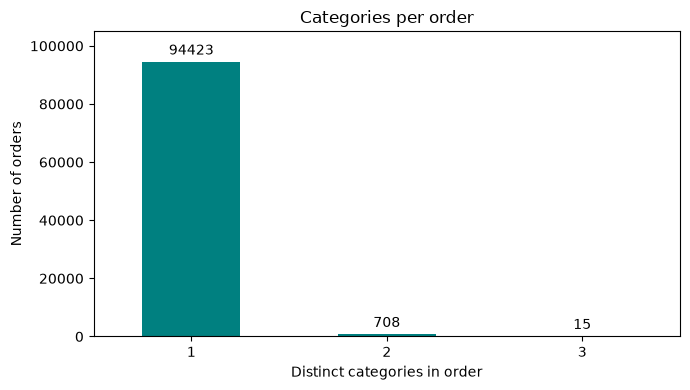

In [8]:
categories_per_order = basket_size.value_counts().sort_index()

ax = categories_per_order.plot.bar(figsize=(7, 4),color="teal")

ax.set_title("Categories per order")
ax.set_xlabel("Distinct categories in order")
ax.set_ylabel("Number of orders")
ax.tick_params(axis="x", rotation=0)
ax.bar_label(ax.containers[0], padding=3)
ax.set_ylim(top=105_000)


plt.tight_layout()
plt.show()

## Train and Test

In [9]:
cutoff_date = pd.Timestamp("2018-05-01")

train = history.loc[history[purchase_date] < cutoff_date].copy()
after_cut = history.loc[history[purchase_date] >= cutoff_date].copy()

known_customers = after_cut[customer].isin(train[customer].unique())

next_order = (after_cut.loc[known_customers, [customer, "order_id", purchase_date]]
    .sort_values([purchase_date, "order_id"])
    .drop_duplicates(customer))

test = after_cut.merge(next_order[[customer, "order_id"]],
    on=[customer, "order_id"],
    validate="many_to_one",)

train_interactions = train[[customer, category]].drop_duplicates()

relevant = test.groupby(customer)[category].agg(set)

out_of_catalog = ~test[category].isin(train_interactions[category])


print("Train orders:", train["order_id"].nunique())
print("Test customers:", len(relevant))
print("Post cutoff customers without history:", after_cut.loc[~known_customers, customer].nunique())
print("Out of atalog test category share:, "f"{(out_of_catalog >= 2).mean():.2%}")

Train orders: 69907
Test customers: 528
Post cutoff customers without history: 24370
Out of atalog test category share:, 0.00%


## Ranked by popularity

In [10]:
train_frequency = (train.groupby(category)["order_id"]
    .nunique()
    .rename("order")
    .reset_index()
    .sort_values(["order", category], ascending=[False, True]))


display(train_frequency.head(10))

,product_category_name,order
13,cama_mesa_banho,6957
32,esporte_lazer,5868
11,beleza_saude,5724
44,informatica_acessorios,5018
54,moveis_decoracao,4851
71,utilidades_domesticas,3776
65,relogios_presentes,3572
69,telefonia,3212
12,brinquedos,3118
26,cool_stuff,3062


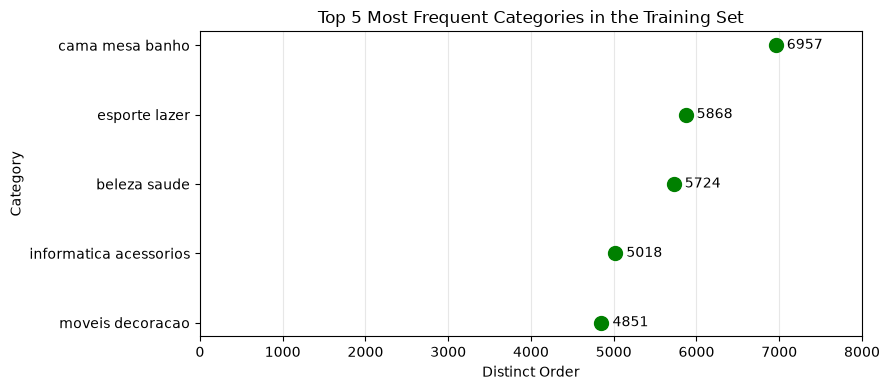

In [11]:
top_5 = (train_frequency.head(5)
       .sort_values("order"))

names = top_5[category].str.replace("_", " ", regex=False)

fig, ax = plt.subplots(figsize=(9, 4))

ax.scatter(top_5["order"], names, color="green", s=100)

for number, names in zip(top_5["order"], names):
    ax.annotate(
        str(number), (number, names), xytext=(8, 0),textcoords = "offset points", va="center")


ax.set_title("Top 5 Most Frequent Categories in the Training Set")
ax.set_xlabel("Distinct Order")
ax.set_ylabel("Category")
ax.set_xlim(0, top_5["order"].max() * 1.15)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)


plt.tight_layout()
plt.show()


In [12]:
categories = train_interactions["product_category_name"].dropna().unique()
print(", ".join(categories))

utilidades_domesticas, pet_shop, papelaria, automotivo, moveis_decoracao, moveis_escritorio, ferramentas_jardim, informatica_acessorios, brinquedos, construcao_ferramentas_construcao, telefonia, cama_mesa_banho, beleza_saude, eletronicos, bebes, cool_stuff, perfumaria, climatizacao, esporte_lazer, livros_interesse_geral, relogios_presentes, alimentos, malas_acessorios, fashion_bolsas_e_acessorios, instrumentos_musicais, market_place, eletrodomesticos, agro_industria_e_comercio, artigos_de_festas, casa_conforto, cds_dvds_musicais, construcao_ferramentas_iluminacao, consoles_games, moveis_quarto, construcao_ferramentas_seguranca, telefonia_fixa, fashion_calcados, casa_construcao, audio, eletrodomesticos_2, eletroportateis, cine_foto, moveis_cozinha_area_de_servico_jantar_e_jardim, industria_comercio_e_negocios, bebidas, artes, fashion_roupa_masculina, construcao_ferramentas_jardim, artigos_de_natal, tablets_impressao_imagem, fashion_esporte, moveis_sala, la_cuisine, flores, alimentos_beb

## Collaborative models and anlysis

##### I chose to keep the functions directly within the notebook in order to consolidate the code,explanations, and results into a single file. 

In [13]:
matrix = pd.crosstab(train_interactions[customer], train_interactions[category])

test_customers = relevant.index
categorys = matrix.columns.to_numpy()
test_histories = matrix.loc[test_customers].to_numpy(dtype=float)
popularity = train_frequency.set_index(category)["order"].reindex(categorys).to_numpy()

def normalize(matrix):
    norms = np.linalg.norm(matrix, axis=1, keepdims=True)
    return matrix / np.where(norms > 0, norms, 1)

def top_categories(score):
    rank = np.lexsort((categorys, -popularity, -score))
    return categorys[rank[:5]].tolist()

# user-user.Excludes the customer themselves from the list of neighbors.
customer_profiles = normalize(matrix.to_numpy(dtype=float))
customer_positions = matrix.index.get_indexer(test_customers)
neighborhood = normalize(test_histories) @ customer_profiles.T
neighborhood[np.arange(len(test_customers)), customer_positions] = 0

per_user = []
for similarities in neighborhood:
    rank = np.argsort(-similarities, kind="stable")[:20]
    score = similarities[rank] @ matrix.to_numpy()[rank]
    per_user.append(top_categories(score))

# Item–item. Each item represents a product category.
category_profiles = normalize(matrix.to_numpy(dtype=float).T)
similarities_items = category_profiles @ category_profiles.T
score_items = (test_histories @ similarities_items) / test_histories.sum(axis=1, keepdims=True)
per_item = [top_categories(score) for score in score_items]

In [14]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


text_categories= [name.replace("_", " ") for name in categorys]

vectorizer = TfidfVectorizer()
content_vectors = vectorizer.fit_transform(text_categories)

content_profiles = (test_histories @ content_vectors.toarray()) / test_histories.sum(axis=1, keepdims=True)

content_similarities = cosine_similarity(content_profiles, content_vectors)

per_content = [top_categories(score)
    for score in content_similarities]


display(pd.DataFrame({
    "Category": categorys,
    "Text used": text_categories}).head(10))

print("Example of content-based recommendations:", per_content[0])

,Category,Text used
0,agro_industria_e_comercio,agro industria e comercio
1,alimentos,alimentos
2,alimentos_bebidas,alimentos bebidas
3,artes,artes
4,artes_e_artesanato,artes e artesanato
5,artigos_de_festas,artigos de festas
6,artigos_de_natal,artigos de natal
7,audio,audio
8,automotivo,automotivo
9,bebes,bebes


Example of content-based recommendations: ['moveis_escritorio', 'moveis_decoracao', 'moveis_sala', 'moveis_quarto', 'moveis_colchao_e_estofado']


In [15]:
recommendations = {
    "popularity": [top_categories(popularity)] * len(test_customers),
    "user-user": per_user,
    "Item–item": per_item,}

result = []

for method, lists in recommendations.items():
    recalls = []


    for suggestions, actual_categories in zip(lists, relevant):
        hits = len(set(suggestions) & actual_categories)
        recalls.append(hits / len(actual_categories))

    result.append({
        "Method": method,
        "Recall@5": np.mean(recalls)})
    

comparison = pd.DataFrame(result).set_index("Method")
display(comparison.round(4))

,Recall@5
Method,
popularity,0.4441
user-user,0.5312
Item–item,0.3920


In [16]:
# Anonymized example: The first record in the test, following the index order.
print("Categories in history:", ", ".join(matrix.columns[test_histories[0] > 0]))
print("Categories in the test order.:", ", ".join(sorted(relevant.iloc[0])))
for method, lists in recommendations.items():
    print(method, "→", ", ".join(lists[0]))

Categories in history: moveis_escritorio
Categories in the test order.: beleza_saude
popularity → cama_mesa_banho, esporte_lazer, beleza_saude, informatica_acessorios, moveis_decoracao
user-user → moveis_escritorio, cama_mesa_banho, esporte_lazer, beleza_saude, informatica_acessorios
Item–item → moveis_escritorio, moveis_sala, moveis_decoracao, cama_mesa_banho, eletrodomesticos_2


In [17]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori as apriori_mlxtend
from mlxtend.frequent_patterns import association_rules


# Reference